# 계절성 검사 및 STL 알고리즘 매칭 데모

## 구현 흐름

1. 필요한 라이브러리와 저장 폴더를 준비한다.
2. 계절성이 있는 월별 예제 데이터를 생성하고 CSV로 저장한다.
3. 저장된 데이터셋을 다시 읽는다.
4. 시계열 구조와 계절성 여부를 검사한다.
5. 검사 결과에 따라 데이터셋 태그를 생성한다.
6. 데이터셋 메타데이터와 STL 알고리즘 메타데이터를 JSON으로 저장한다.
7. 모든 메타데이터 JSON을 읽어 하나의 JSON으로 통합한다.
8. 데이터셋 태그와 STL 필수 태그를 비교한다.
9. STL 적용이 가능하면 시계열 분해를 실행한다.
10. STL 분해 결과를 표준 JSON 형식으로 저장한다.

In [1]:
# 라이브러리 설치
%pip install pandas numpy statsmodels matplotlib

Note: you may need to restart the kernel to use updated packages.


## 1. 라이브러리 및 경로 설정

데이터 처리에는 pandas와 NumPy를 사용하고, 시계열 분해에는 statsmodels의 STL을 사용한다.

실행 결과로 생성되는 데이터, 메타데이터, 분석 결과를 각각 다른 폴더에 저장한다.

In [2]:
# 라이브러리 및 폴더 설정
from pathlib import Path
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from statsmodels.tsa.seasonal import STL


# 현재 주피터 노트북이 실행되는 위치
BASE_DIR = Path.cwd()

# 파일 종류별 저장 폴더
DATA_DIR = BASE_DIR / "data"
METADATA_DIR = BASE_DIR / "metadata"
RESULT_DIR = BASE_DIR / "results"

# 폴더가 없으면 생성
DATA_DIR.mkdir(parents=True, exist_ok=True)
METADATA_DIR.mkdir(parents=True, exist_ok=True)
RESULT_DIR.mkdir(parents=True, exist_ok=True)

print("기준 경로:", BASE_DIR)
print("데이터 폴더:", DATA_DIR)
print("메타데이터 폴더:", METADATA_DIR)
print("결과 폴더:", RESULT_DIR)

기준 경로: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)
데이터 폴더: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\data
메타데이터 폴더: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\metadata
결과 폴더: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\results


## 2. 계절성이 있는 예제 데이터 생성

5년 동안의 월별 데이터를 생성한다.

데이터는 다음 세 부분으로 구성한다.

- 장기적으로 증가하는 추세
- 12개월마다 반복되는 계절성
- 실제 데이터와 비슷하게 만들기 위한 무작위 잡음

생성한 데이터는 CSV로 저장한다.

In [ ]:
# 계절성 예제 데이터 생성
# 실행할 때마다 동일한 난수가 나오도록 고정
np.random.seed(42)

# 2020년 1월부터 60개월, 즉 5년의 월별 날짜 생성
dates = pd.date_range(
    start="2020-01-01", # 시작 날짜
    periods=60, # 생성할 날짜 개수
    freq="MS", # 매월 1일 간격 example: 2020-01-01, 2020-02-01, 2020-03-01, ...
)

# 0부터 59까지의 시간 순서
time_index = np.arange(60)

# 시간이 흐를수록 조금씩 증가하는 추세
trend = 100 + time_index * 0.5

# 12개월마다 반복되는 계절성 
# ( seasonal_pattern 은 대략 -20부터 20사이를 반복 => 1년동안 증가했다가 감소하고 그 다음 해에 같은 움직임 반복)
seasonal_pattern = (
    20 # 계절성 변동의 크기
    * np.sin( # 사인 함수를 이용한 계절성 패턴 생성 , 위아래로 반복되는 sine 곡선
        2 * np.pi # 사인 함수의 한 주기를 완성하기 위한 값
        * time_index / 12 # 12개월 주기로 반복되도록 설정
    )
)

# 실제 데이터처럼 약간의 불규칙성을 추가
noise = np.random.normal(
    loc=0, # 난수의 평균 0
    scale=3, # 난수의 표준편차 3
    size=60, # 난수의 개수 60개
)

# 최종 관측값
values = (
    trend
    + seasonal_pattern
    + noise
)

# DataFrame 생성 (날짜별 관측값을 가진 시계열 데이터셋)
demo_df = pd.DataFrame({
    "date": dates,
    "value": values,
})

# 예제 데이터 저장 경로
data_path = (
    DATA_DIR
    / "seasonal_demo.csv"
)

# CSV 파일로 저장
demo_df.to_csv(
    data_path,
    index=False,
    encoding="utf-8-sig",
)

print("예제 데이터 저장 완료:", data_path)

display(demo_df.head())

예제 데이터 저장 완료: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\data\seasonal_demo.csv


,date,value
0,2020-01-01,101.490142
1,2020-02-01,110.085207
2,2020-03-01,120.263574
3,2020-04-01,126.069090
4,2020-05-01,118.618048


## 3. 저장된 데이터셋 읽기

생성한 DataFrame을 바로 사용하지 않고, CSV 파일을 다시 읽는다.

이를 통해 실제 데이터 파일이 입력되었을 때와 같은 흐름으로 데모를 진행한다.

In [ ]:
# 데이터 읽기 및 자료형 변환
# 저장된 CSV 파일 읽기
dataset_df = pd.read_csv(
    data_path,
    encoding="utf-8-sig",
) # demo_df는 직접 만든 데이터, dataset_df는 CSV에서 다시 읽은 데이터

# 분석에 사용할 컬럼 지정
time_column = "date" # 시간 정보가 들어있는 열
value_column = "value" # 계절성을 검사할 숫자 열

# 날짜 컬럼을 datetime 자료형으로 변환 (STL과 상관계수 계산이 문자열이 아닌 숫자를 요구)
dataset_df[time_column] = pd.to_datetime(
    dataset_df[time_column], # data열을 선택
    errors="coerce", # 날짜로 바꿀 수 없는 값은 NaT로 처리
)

# 분석값을 숫자 자료형으로 변환
dataset_df[value_column] = pd.to_numeric(
    dataset_df[value_column],
    errors="coerce",
)

# 날짜순으로 정렬
dataset_df = (
    dataset_df
    .sort_values(time_column)
    .reset_index(drop=True) 
)

print("데이터 크기:", dataset_df.shape)

print("\n자료형:")
print(dataset_df.dtypes)

display(dataset_df.head())

데이터 크기: (60, 2)

자료형:
date     datetime64[ns]
value           float64
dtype: object


,date,value
0,2020-01-01,101.490142
1,2020-02-01,110.085207
2,2020-03-01,120.263574
3,2020-04-01,126.069090
4,2020-05-01,118.618048


## 4. 시계열 구조 검사

이 데이터가 월별 시계열 분석에 사용할 수 있는 형태인지 검사한다.

시계열 데이터 여부를 다음 조건으로 검사한다.

1. 날짜 컬럼이 존재한다.
2. 분석 대상 컬럼이 존재한다.
3. 날짜 컬럼이 datetime 자료형이다.
4. 분석 대상 컬럼이 숫자형이다.
5. 관측 간격이 일정하다.
6. 결측값이 없다.

월별 계절성을 검사하므로 계절 주기는 12로 설정한다.  
STL 적용을 위해 최소 두 번 이상의 계절 주기, 즉 24개월 이상의 데이터가 필요하다고 설정한다.

In [ ]:
# 월별 데이터의 연간 계절 주기 (12월)
seasonal_period = 12 

# 기본 컬럼 조건 확인 
# 날짜 열이 존재하는지 확인
has_time_column = (
    time_column in dataset_df.columns
)
# 분석값 열이 존재하는지 확인
has_value_column = (
    value_column in dataset_df.columns
)

# 자료형 확인
# 날짜 자료형인지 확인 ( 날짜 자료형 True, 문자/숫자 자료형 False )
is_datetime = pd.api.types.is_datetime64_any_dtype(
    dataset_df[time_column]
)

# 숫자 자료형인지 확인 (정수형, 실수형 True)
is_numeric = pd.api.types.is_numeric_dtype(
    dataset_df[value_column]
)

# 결측치 확인 (결측값 없음 True, 결측값 있음 False)
has_no_missing_values = (
    dataset_df[
        [time_column, value_column]
    ]
    .isna()
    .sum()
    .sum()
    == 0
)

# 날짜 컬럼을 인덱스로 사용하는 시계열 생성
series = (
    dataset_df
    .set_index(time_column)[value_column] # 날짜를 인덱스로 설정하고 분석값 열 선택
    .sort_index()
)

# 날짜 간격 추정 - series의 인덱스(날짜)를 보고 관측 간격을 자동으로 추정
inferred_frequency = pd.infer_freq(
    series.index
) # 현재 날짜는 한달 간격 = inferred_frequency == "MS"

# 월별 시작일 간격인지 확인
is_regular_interval = (
    inferred_frequency == "MS"
)

# 최소 두 번 이상의 계절 주기가 있는지 확인
has_enough_data = (
    len(series)
    >= seasonal_period * 2
)

# 기본적인 시계열 데이터 여부 - 모두 True이면 시계열 데이터로 판단
is_time_series = all([
    has_time_column, # 날짜열 존재
    has_value_column, # 분석할 값 존재
    is_datetime, # 날짜 열이 날짜 자료형인지 
    is_numeric, # 분석값 열이 숫자 자료형인지
])

print("시계열 여부:", is_time_series)
print("추정 시간 간격:", inferred_frequency)
print("일정한 월별 간격:", is_regular_interval)
print("결측값 없음:", has_no_missing_values)
print("충분한 데이터 길이:", has_enough_data)

시계열 여부: True
추정 시간 간격: MS
일정한 월별 간격: True
결측값 없음: True
충분한 데이터 길이: True


## 5. 계절성 여부 검사

계절성은 일정한 주기로 비슷한 패턴이 반복되는 성질이다.

월별 데이터이므로 현재 값과 12개월 전 값의 상관성을 계산한다.  
장기 추세가 계절성 점수에 영향을 주지 않도록 먼저 선형 추세를 제거한다.

계절성 점수가 0.5 이상이면 계절성이 있다고 판정한다.

이 임계값은 절대적인 기준이 아니라 이번 데모에서 사용하는 운영 기준이다.

In [ ]:
# 계절성 검사 함수
def check_seasonality(
    series, # 계절성을 검사할 시계열 데이터
    period, # 계절성 주기 (예: 월별 데이터의 경우 12)
    threshold=0.5, # 상관계수 기준값 (0~1 사이) 0.5 이상이면 계절성 존재로 판단
):
    """
    선형 추세를 제거한 뒤,
    지정한 주기만큼 떨어진 값들의 상관성을 계산한다.
    """

    # 시계열 정리 - 결측값 제거 후 숫자형으로 변환
    clean_series = (
        pd.Series(series)
        .dropna()
        .astype(float)
        .reset_index(drop=True)
    )

    # 최소 두 번 이상의 주기가 필요
    minimum_length = period * 2

    # 데이터가 부족한지 확인 ( 정리된 데이터 길이가 필요한 최소 길이보다 짧은지 확인)
    if len(clean_series) < minimum_length:
        return {
            "method": "detrended_lag_correlation", # 사용한 계절성 검사 방법( 추세를 제거한 다음 지정한 주기만큼 떨어진 값들의 상관성을 계산하는 방법)
            "period": int(period),
            "score": None,
            "threshold": float(threshold),
            "detected": False,
            "reason": "계절성 검사에 필요한 데이터가 부족합니다.",
        }

    # 시간 순서를 0, 1, 2, ... 형태로 생성
    x = np.arange(
        len(clean_series) # 60
    )

    # 데이터의 선형 추세 계산
    trend_coefficients = np.polyfit( # 데이터에 가장 잘 맞는 선을 찾는 함수
        x, # 시간 순서
        clean_series, # 시간의 관측값 
        deg=1, # 1차식 사용 ax + b
    )

    # 앞에서 구한 직선식을 이용해 각 시점의 추세값을 계산
    estimated_trend = np.polyval( # 기울기와 절편으로 각 시점의 추세값 계산
        trend_coefficients,
        x,
    )

    # 원래 값에서 추세를 제거 -> 단순한 증가 흐름을 계절성으로 잘못 판단하지 않기 위해
    detrended_values = (
        clean_series.to_numpy()
        - estimated_trend # 원래 관측값에서 추세값을 빼서 추세를 제거
    )


    # period(12)만큼 떨어진 값들의 상관성을 계산하기 위해 두 집합으로 나눔
    # 앞부분 값
    previous_values = (
        detrended_values[:-period] # 마지막 12개 제외
    )

    # period만큼 뒤의 값
    current_values = (
        detrended_values[period:] # 처음 12개 제외
    )

    # 두 값 집합 중 하나라도 변화가 없으면 상관계수는 0 (표준편차)
    if (
        np.std(previous_values) == 0
        or np.std(current_values) == 0
    ):
        score = 0.0

    else:
        # period(12)만큼 떨어진 값들의 상관계수
        score = float(
            np.corrcoef(
                previous_values,
                current_values,
            )[0, 1] # 1에 가까움 > 거의 같은 방향, -1에 가까움 > 반대 방향, 0에 가까움 > 특별한 관계 없음
        )

    # 정해둔 기준 이상이면 계절성 존재
    detected = bool(
        score >= threshold # 0.5 이상이면 계절성 존재로 판단
    )

    return {
        "method": "detrended_lag_correlation",
        "period": int(period),
        "score": score,
        "threshold": float(threshold),
        "detected": detected,
        "reason": (
            "반복 상관성이 기준 이상입니다."
            if detected
            else "반복 상관성이 기준보다 낮습니다."
        ),
    }

In [ ]:
# 계절성 검사 실행
# 계절성 판정 기준
seasonality_threshold = 0.5

# 계절성 검사 실행
seasonality_result = check_seasonality( # 계절성 검사 함수 호출
    series=series,
    period=seasonal_period,
    threshold=seasonality_threshold,
)

# 결과 딕셔너리를 JSON 문자열로 변환하여 출력
print(json.dumps( # 파이썬 딕셔너리를 JSON 문자열로 변환
    seasonality_result,
    ensure_ascii=False, # 
    indent=2,
))

{
  "method": "detrended_lag_correlation",
  "period": 12,
  "score": 0.960437483259565,
  "threshold": 0.5,
  "detected": true,
  "reason": "반복 상관성이 기준 이상입니다."
}


## 6. 데이터셋 태그 생성

데이터 구조와 계절성 검사 결과에 따라 태그를 생성한다.

생성 가능한 주요 태그는 다음과 같다.

- `time-series`: 시계열 데이터
- `monthly`: 월별 데이터
- `numeric-target`: 숫자형 분석값 보유
- `regular-interval`: 시간 간격이 일정함
- `seasonal`: 계절성이 탐지됨

In [ ]:
# STL 적용 가능 조건 - 모두 만족하면 True-> STL 적용 가능
is_stl_applicable = all([
    # 변수들 4번에 정의되어 있음
    is_time_series, # 이 데이터가 시계열 데이터인지
    is_regular_interval, # 날짜 간격이 일정한지
    has_no_missing_values, # 결측값이 없는지
    has_enough_data, # 충분한 데이터가 있는지
    seasonality_result["detected"], # 계절성이 존재하는지 (12개월마다 반복되는 패턴이 있는지)
]) 

# 기본 태그
dataset_tags = [] # 데이터셋에 대한 태그를 저장할 리스트

if is_time_series: # 시계열 데이터 태그
    dataset_tags.append("time-series")

if inferred_frequency == "MS": # 월별 태그
    dataset_tags.append("monthly")

if is_numeric:
    dataset_tags.append("numeric-target") # 숫자형 분석값 태그

# 시간 간격 태그
if is_regular_interval:
    dataset_tags.append("regular-interval") # 규칙
else: 
    dataset_tags.append("irregular-interval") # 불규칙

# 계절성 태그
if seasonality_result["detected"]:
    dataset_tags.append("seasonal") # 탐지
else:
    dataset_tags.append("non-seasonal") # 탐지 X

# 중복 제거 후 정렬
dataset_tags = sorted(
    set(dataset_tags)
)

print("STL 적용 가능:", is_stl_applicable)
print("생성 태그:", dataset_tags)

STL 적용 가능: True
생성 태그: ['monthly', 'numeric-target', 'regular-interval', 'seasonal', 'time-series']


## 7. 데이터셋 및 알고리즘 메타데이터 저장

데이터셋 메타데이터에는 데이터의 구조, 계절성 검사 결과, 생성된 태그를 저장한다.

알고리즘 메타데이터에는 STL을 적용하기 위해 필요한 태그와 출력 형식을 저장한다.

#### 데이터셋 메타데이터

In [ ]:
# 데이터셋 메타데이터 저장
dataset_metadata = {
    "metadata_type": "dataset", # 데이터셋 메타데이터 유형

    "dataset_id": "SEASONAL_DEMO_01", # 데이터셋 고유 ID

    "dataset_name": "월별 계절성 예제 데이터", # 데이터셋 이름

    "source_file": data_path.name, # 데이터셋 원본 파일 이름

    # 데이터 구조 정보 저장
    "schema": {
        # 데이터셋의 행 개수
        "row_count": int( 
            len(dataset_df)
        ),
        # 데이터셋의 열 개수
        "time_column": time_column,
        # 데이터셋의 열 개수
        "value_column": value_column,
    },

    # 시계열 정보 저장
    "time_series": {
        # 기본적 시계열 여부
        "is_time_series": bool(
            is_time_series
        ),
        "frequency": inferred_frequency, # 추정한 시간 간격 저장
        "is_regular_interval": bool( # 관측 간격이 일정한지 저장
            is_regular_interval
        ),
        # 데이터 시작일과 종료일 저장
        "start_date": (
            series.index.min()
            .strftime("%Y-%m-%d")
        ),
        "end_date": (
            series.index.max()
            .strftime("%Y-%m-%d")
        ),
    },
    # 계절성 검사 결과와 태그 저장
    "seasonality": seasonality_result,

    "tags": dataset_tags,
}

# 데이터셋 메타데이터를 JSON 파일로 저장
dataset_metadata_path = (
    METADATA_DIR
    / "seasonal_demo_dataset_metadata.json"
)

with open(
    dataset_metadata_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        dataset_metadata,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "데이터셋 메타데이터 저장:",
    dataset_metadata_path,
)

데이터셋 메타데이터 저장: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\metadata\seasonal_demo_dataset_metadata.json


#### 알고리즘 메타데이터

In [ ]:
# STL 알고리즘 메타데이터 저장
stl_metadata = {
    "metadata_type": "algorithm",

    "algorithm_id": "STL_01",

    "algorithm_name": "STL",

    "category": "time-series-decomposition",

    # STL과 매칭되기 위해 데이터셋이 가져야 할 태그
    "required_tags": [
        "time-series", # 시계열 데이터
        "numeric-target", # 숫자형 분석값
        "regular-interval", # 일정한 시간 간격
        "seasonal", # 계절성 존재
    ],

    # STL 알고리즘에 필요한 파라미터 정보
    "parameters": {
        "period": int(
            seasonal_period # 계절성 주기 저장
        ),
        "robust": True, # 이상치의 영향을 줄이도록 STL을 실행하겠다는 설정
    },

    "outputs": [
        "observed", # 원본 관측값
        "trend", # 추세값
        "seasonal", # 계절성값
        "residual", # 추세와 계절성으로 설명되지 않는 나머지
    ],
}

# STL 메타데이터 저장
stl_metadata_path = (
    METADATA_DIR
    / "stl_algorithm_metadata.json"
)

with open(
    stl_metadata_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        stl_metadata,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "STL 메타데이터 저장:",
    stl_metadata_path,
)

STL 메타데이터 저장: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\metadata\stl_algorithm_metadata.json


## 8. 메타데이터 통합

metadata 폴더에 저장된 데이터셋별 메타데이터와 알고리즘별 메타데이터를 모두 읽는다.

읽어온 JSON을 데이터셋 목록과 알고리즘 목록으로 구분하여 하나의 통합 JSON으로 저장한다.

흐름

metadata 폴더의 JSON 파일 검색

→ JSON 하나씩 읽기

→ 데이터셋과 알고리즘으로 분류

→ 하나의 딕셔너리로 합치기

→ integrated_metadata.json으로 저장

In [ ]:
# 두 종류의 메타데이터를 따로 모으기 위한 빈 리스트 생성
dataset_metadata_list = [] # 데이터셋 메타데이터
algorithm_metadata_list = [] # 알고리즘 메타데이터

# metadata 폴더의 JSON 파일을 모두 확인
for json_path in sorted(
    METADATA_DIR.glob("*.json")
):
    # 이전 실행에서 만든 통합 파일은 제외
    # 통합 파일 안에 이전 통합 결과가 다시 들어가는 문제가 생길 수 있기 때문
    if json_path.name == "integrated_metadata.json":
        continue

    # JSON 읽기 -> 파이썬 딕셔너리 변환
    with open(
        json_path,
        "r",
        encoding="utf-8",
    ) as file:
        metadata = json.load(file)

    # metadata_type이 없는 기존 메타데이터도 구조를 보고 분류
    if ( # 데이터셋 메타데이터인 경우
        metadata.get("metadata_type") == "dataset"
        or "dataset_info" in metadata
    ):
        dataset_metadata_list.append(
            metadata
        )

    elif ( # 알고리즘 메타데이터인 경우
        metadata.get("metadata_type") == "algorithm"
        or "algorithm_id" in metadata
    ):
        algorithm_metadata_list.append(
            metadata
        )

# 하나의 통합 메타데이터 구조
integrated_metadata = {
    "metadata_version": "1.0",

    "dataset_count": len(
        dataset_metadata_list
    ),

    "algorithm_count": len(
        algorithm_metadata_list
    ),

    "datasets": dataset_metadata_list,

    "algorithms": algorithm_metadata_list,
}

# 통합 메타데이터 저장 경로
integrated_metadata_path = (
    METADATA_DIR
    / "integrated_metadata.json"
)

with open(
    integrated_metadata_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        integrated_metadata,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "통합 메타데이터 저장:",
    integrated_metadata_path,
)

print(
    "데이터셋 메타데이터 수:",
    len(dataset_metadata_list),
)

print(
    "알고리즘 메타데이터 수:",
    len(algorithm_metadata_list),
)

통합 메타데이터 저장: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\metadata\integrated_metadata.json
데이터셋 메타데이터 수: 1
알고리즘 메타데이터 수: 1


## 9. 데이터셋과 STL 알고리즘 매칭

데이터셋이 가진 태그와 STL 알고리즘이 요구하는 태그를 비교한다.

STL의 필수 태그가 데이터셋 태그에 모두 포함되어 있으면 적용 가능하다고 판정한다.

In [ ]:
# 태그 기반 알고리즘 매칭

# 데이터셋이 실제로 가진 태그
dataset_tag_set = set(
    dataset_metadata["tags"]
)

# STL이 요구하는 필수 태그
required_tag_set = set(
    stl_metadata["required_tags"]
)

# 데이터셋에 없는 필수 태그 ( 두 집합의 차집합 )
missing_tags = sorted(
    required_tag_set
    - dataset_tag_set
)

# 누락된 필수 태그가 없으면 적용 가능
is_matched = (
    len(missing_tags) == 0
)

# 매칭 결과 표준 구조
matching_result = {
    # 데이터셋 ID 저장
    "dataset_id": (
        dataset_metadata["dataset_id"]
    ),
    # 알고리즘 ID 저장
    "algorithm_id": (
        stl_metadata["algorithm_id"]
    ),
    # 알고리즘 이름 저장
    "algorithm_name": (
        stl_metadata["algorithm_name"]
    ),
    # STL 적용 가능 여부 저장
    "applicable": bool(
        is_matched
    ),
    # 데이터셋이 가진 태그 저장
    "dataset_tags": sorted(
        dataset_tag_set
    ),
    # STL이 요구하는 필수 태그 저장
    "required_tags": sorted(
        required_tag_set
    ),
    # 데이터셋에 없는 필수 태그 저장
    "missing_tags": missing_tags,
    # 매칭 결과 이유 저장
    "reason": (
        "STL 필수 태그를 모두 만족합니다."
        if is_matched
        else "STL 적용에 필요한 태그가 부족합니다."
    ),
}

print(json.dumps(
    matching_result,
    ensure_ascii=False,
    indent=2,
))

{
  "dataset_id": "SEASONAL_DEMO_01",
  "algorithm_id": "STL_01",
  "algorithm_name": "STL",
  "applicable": true,
  "dataset_tags": [
    "monthly",
    "numeric-target",
    "regular-interval",
    "seasonal",
    "time-series"
  ],
  "required_tags": [
    "numeric-target",
    "regular-interval",
    "seasonal",
    "time-series"
  ],
  "missing_tags": [],
  "reason": "STL 필수 태그를 모두 만족합니다."
}


In [13]:
# 매칭 결과 저장
matching_result_path = (
    RESULT_DIR
    / "matching_result.json"
)

with open(
    matching_result_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        matching_result,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "매칭 결과 저장:",
    matching_result_path,
)

매칭 결과 저장: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\results\matching_result.json


## 10. STL 실행 및 결과 JSON 표준화

데이터셋과 STL의 매칭 결과가 적용 가능일 때만 STL을 실행한다.

STL은 원본 시계열을 다음 네 가지 항목으로 출력한다.

- `observed`: 원래 관측값
- `trend`: 장기적인 추세
- `seasonal`: 반복되는 계절성
- `residual`: 추세와 계절성을 제외한 잔차

분해 결과는 다른 데이터셋에도 동일한 구조로 적용할 수 있도록 JSON으로 표준화한다.

In [ ]:
# STL 적용 가능 여부 확인
if not matching_result["applicable"]:
    raise ValueError(
        "현재 데이터셋에는 STL을 적용할 수 없습니다."
    )

# STL 모델 생성
stl_model = STL(
    series, # 날짜 인덱스 기반 시계열 (분해할 대상)
    period=seasonal_period, # 계절성의 주기 (월별 데이터의 경우 12)
    robust=True, # 이상치의 영향을 덜 받도록 STL을 실행
)

# STL 분해 실행
stl_result = stl_model.fit()

print("STL 분해 완료")

STL 분해 완료


실행 후 stl_result에 다음 결과가 들어감
| 코드 | 의미 |
|---|---|
| `stl_result.observed` | 원래 관측값 |
| `stl_result.trend` | 장기적인 추세 |
| `stl_result.seasonal` | 반복되는 계절성 |
| `stl_result.resid` | 추세와 계절성을 제외한 잔차 |

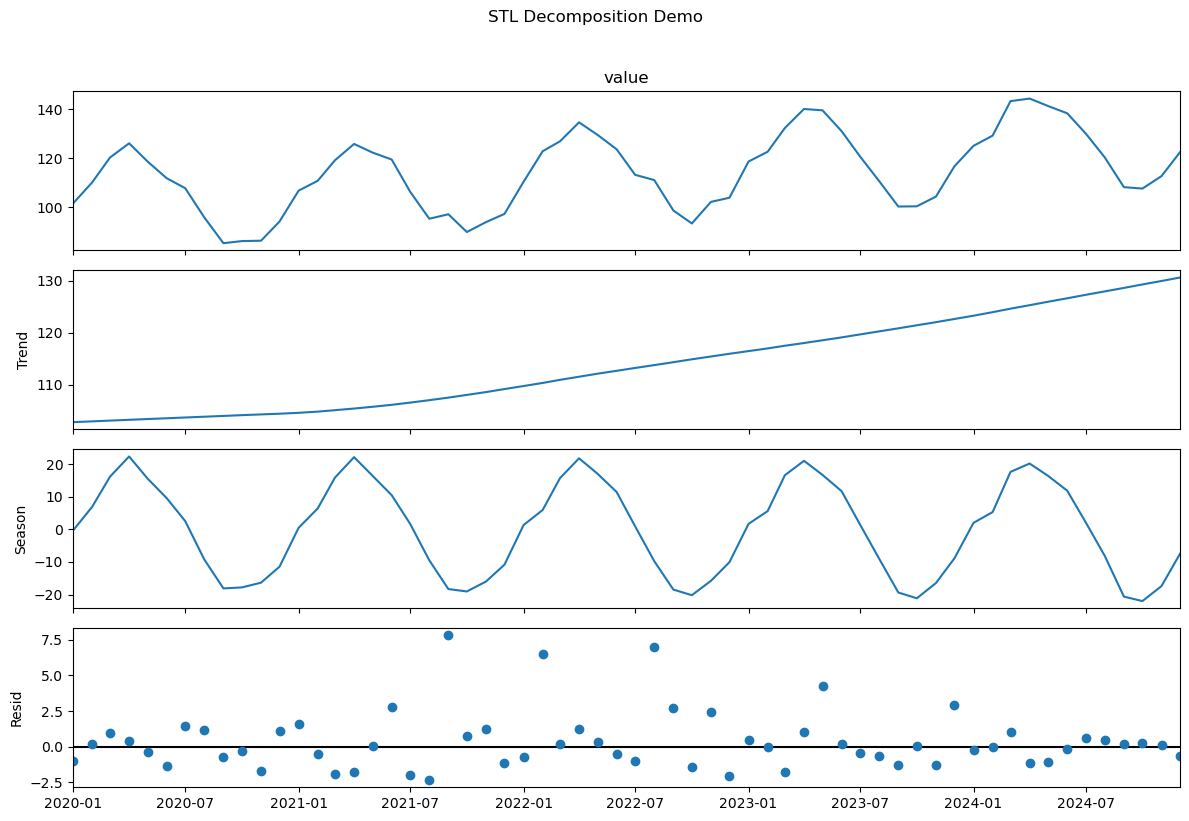

In [15]:
# STL 결과 시각화
figure = stl_result.plot()

figure.set_size_inches(12, 8)

plt.suptitle(
    "STL Decomposition Demo",
    y=1.02,
)

plt.tight_layout()
plt.show()

Observed  → 원래 데이터

Trend     → 장기적인 추세

Seasonal  → 반복되는 계절성

Resid     → 남은 잔차

In [ ]:
# STL 결과를 JSON으로 표준화

# STL 결과를 표 형태로 구성
stl_result_df = pd.DataFrame({
    # 날짜 열 만들기
    "date": (
        series.index
        .strftime("%Y-%m-%d")
    ),

    # 원래 관측값 열 만들기
    "observed": (
        stl_result.observed
        .astype(float)
    ),

    # 추세 열 만들기
    "trend": (
        stl_result.trend
        .astype(float)
    ),

    # 계절성 열 만들기
    "seasonal": (
        stl_result.seasonal
        .astype(float)
    ),

    # 잔차 열 만들기
    "residual": (
        stl_result.resid
        .astype(float)
    ),
})

# 공통 JSON 결과 구조
standardized_stl_result = {
    "result_type": (
        "time-series-decomposition"
    ),

    "dataset_id": (
        dataset_metadata["dataset_id"]
    ),

    "algorithm_id": (
        stl_metadata["algorithm_id"]
    ),

    "algorithm_name": "STL",

    "execution_status": "success",

    "parameters": {
        "time_column": time_column,
        "value_column": value_column,
        "frequency": inferred_frequency,
        "period": int(
            seasonal_period
        ),
        "robust": True,
    },

    "components": [
        "observed",
        "trend",
        "seasonal",
        "residual",
    ],

    "result_count": int(
        len(stl_result_df)
    ),

    "results": (
        stl_result_df
        .to_dict(orient="records")
    ),
}

In [17]:
# STL 결과 JSON 저장
stl_result_path = (
    RESULT_DIR
    / "stl_decomposition_result.json"
)

with open(
    stl_result_path,
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        standardized_stl_result,
        file,
        ensure_ascii=False,
        indent=2,
    )

print(
    "STL 결과 저장:",
    stl_result_path,
)

STL 결과 저장: c:\Users\k20sh\OneDrive\바탕 화면\tour-data-pipeline(간단 버전)-20261027T011339Z-1-001\tour-data-pipeline(간단 버전)\results\stl_decomposition_result.json


## 11. 최종 결과 확인

모든 단계가 정상적으로 실행되었는지 생성된 파일을 확인한다.

In [18]:
output_files = [
    data_path,
    dataset_metadata_path,
    stl_metadata_path,
    integrated_metadata_path,
    matching_result_path,
    stl_result_path,
]

for output_file in output_files:
    print(
        output_file.name,
        "->",
        output_file.exists(),
    )

seasonal_demo.csv -> True
seasonal_demo_dataset_metadata.json -> True
stl_algorithm_metadata.json -> True
integrated_metadata.json -> True
matching_result.json -> True
stl_decomposition_result.json -> True
